# Deployment

To use the model on new data, we use the functions in `src/predict.py`:

| Entry point | Use case |
|---|---|
| `load_artifacts()` | Load a saved run: model, scalers and settings |
| `predict_next_day()` | Predict the close of the next trading day |
| `simulate_recent()` | Replay recent days using only the data known on each day |

The deployed model is the best version from the modeling iteration in notebook 05: the GRU with the log-return target, chosen by validation RMSE in dollars.

This is a historical demonstration, not a current stock-price forecast: the data ends on September 29, 2026.

[`docs/05_deployment.md`](../docs/05_deployment.md)

In [ ]:
""" Notebook setup: make the project's modules (config.py, src/) importable """
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if "TF_CPP_MIN_LOG_LEVEL" not in os.environ:
    os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow info/warning logs
if os.name == "nt":  # Windows: expose the conda env's CUDA/cuDNN DLLs so TensorFlow can find the GPU
    os.environ["PATH"] = os.path.join(sys.prefix, "Library", "bin") + os.pathsep + os.environ["PATH"]

In [ ]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config
from src.notebook import show_source
from src.data_loader import load_stock_data
from src.evaluate import METRIC_COLUMNS, predict_split, regression_metrics, reload_prepared_run
from src.predict import load_artifacts, predict_next_day, simulate_recent
from src import plotting

plotting.set_plot_style()

2026-11-15 14:27:19.520211: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-15 14:27:19.595608: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-15 14:27:19.596280: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## Choose the model to deploy
Notebook 03 selected `gru_close_volume` by validation loss, and notebook 05 improved it with hyperparameter tuning and a log-return target. The three versions predict different targets, so their validation losses cannot be compared. Notebook 05 compared them by **validation RMSE in dollars** instead, saved in `artifacts/improvements_validation.csv`. We deploy the version with the lowest validation RMSE. Model selection must never use the test set.

In [ ]:
improvements = pd.read_csv(config.ARTIFACTS_DIR / "improvements_validation.csv", index_col=0)
best_run = improvements[improvements["kind"] == "model"]["RMSE"].idxmin()
best_dir = config.ARTIFACTS_DIR / best_run

print("Deploying run:", best_run)
print("Artifact files:", sorted(p.name for p in best_dir.iterdir()))
improvements.round(4)

Deploying run: gru_close_volume_log_return
Artifact files: ['feature_scaler.joblib', 'history.json', 'metadata.json', 'model.keras', 'target_scaler.joblib']


,kind,MAE,RMSE,MAPE_%,DirAcc_%
run,,,,,
Naive baseline,baseline,2.0512,2.7110,1.3029,NaN
Random walk + drift,baseline,2.0540,2.7147,1.3049,51.1111
gru_close_volume_log_return,model,2.0762,2.7317,1.3183,50.9524
gru_close_volume_tuned,model,2.5148,3.2684,1.6186,53.1746
gru_close_volume,model,2.7671,3.4644,1.7474,52.6984
5-day moving average,baseline,3.1819,3.9911,2.0092,49.0476


**The model file alone is not enough.** To make a correct prediction we must repeat the training time preprocessing exactly with the same features, the same lookback and the same fitted scalers. `metadata.json` records those settings. For the log-return model the inputs are log-return features and the output is a log return, so `target_mode` tells `predict_next_day` to rebuild the price as $C_t \cdot e^{\hat r}$.

In [ ]:
print(json.dumps(json.loads((best_dir / "metadata.json").read_text()), indent=2))

{
  "run_name": "gru_close_volume_log_return",
  "model_name": "gru",
  "target_mode": "log_return",
  "feature_columns": [
    "log_return",
    "log_volume",
    "volume_change"
  ],
  "lookback": 60,
  "hparams": {
    "units": 64,
    "kernel_size": 5,
    "dropout": 0.2,
    "learning_rate": 0.001,
    "batch_size": 32
  },
  "epochs_run": 24,
  "best_epoch": 14,
  "best_val_loss": 0.3913681209087372,
  "n_parameters": 13313,
  "train_seconds": 30.2,
  "trained_at": "2026-11-11T21:14:04",
  "tensorflow_version": "2.16.2"
}


**Serialization check.** Reload the saved run, rebuild the data with its saved scalers, and confirm that its test metrics match the ones notebook 05 reported in `artifacts/improvements_test.csv`.

In [ ]:
saved, saved_data = reload_prepared_run(best_run)
reloaded_predictions = predict_split(saved.model, saved_data)
reloaded_metrics = regression_metrics(reloaded_predictions["actual"], reloaded_predictions["predicted"], reloaded_predictions["close_t"])
reported_metrics = pd.read_csv(config.ARTIFACTS_DIR / "improvements_test.csv", index_col=0).loc[best_run, METRIC_COLUMNS].astype(float)

for metric in ("MAE", "RMSE"):
    assert abs(reloaded_metrics[metric] - reported_metrics[metric]) < 1e-3, metric
print("Saved model reloaded: test metrics match notebook 05.")
pd.DataFrame({"reloaded": reloaded_metrics, "notebook 05": reported_metrics}).round(4)

2026-11-15 14:27:21.629990: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:282] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Saved model reloaded: test metrics match notebook 05.


,reloaded,notebook 05
MAE,2.8642,2.8642
RMSE,4.1728,4.1728
MAPE_%,1.1968,1.1968
DirAcc_%,53.7975,53.7975


## Predict the next trading day

In [ ]:
""" Inspect predict_next_day """
show_source(predict_next_day)


<details>
<summary>View implementation of <code>predict_next_day</code></summary>

```python
def predict_next_day(
    artifacts: Union[str, Path, dict],
    df: Optional[pd.DataFrame] = None,
) -> dict:
    """
    Predict the close of the trading day after the last row of `df`.

    Parameters
    ----------
    artifacts : artifact folder path, or the dict returned by load_artifacts().
    df        : clean Close/Volume DataFrame (from load_stock_data). Defaults to config.DATA_PATH.

    Returns
    -------
    dict with last_date, last_close, next_date (estimated), predicted_return,
    predicted_close and predicted_change_pct.
    """
    if not isinstance(artifacts, dict):
        artifacts = load_artifacts(artifacts)
    meta = artifacts["metadata"]
    lookback = meta["lookback"]
    feature_columns = meta["feature_columns"]
    target_mode = meta["target_mode"]

    if df is None:
        # Use the full file: only the most recent `lookback` rows matter here.
        df = load_stock_data(config.DATA_PATH, start_date=None, verbose=False)

    # Same feature engineering as training (keeps the latest row).
    frame = build_inference_frame(df)
    if len(frame) < lookback:
        raise ValueError(f"Need at least {lookback} rows of features, got {len(frame)}.")

    # Take the most recent window and scale it with the TRAINING scaler.
    window = frame[feature_columns].to_numpy()[-lookback:]
    # Add the batch dimension: (lookback, n_features) -> (1, lookback, n_features).
    x = artifacts["feature_scaler"].transform(window)[np.newaxis, ...].astype("float32")

    # Predict (scaled) and convert back to original units, then to a price.
    pred_scaled = artifacts["model"].predict(x, verbose=0).reshape(-1, 1)
    pred_target = float(artifacts["target_scaler"].inverse_transform(pred_scaled)[0, 0])
    last_close = float(frame["Close"].iloc[-1])
    predicted_close = float(to_price(pred_target, last_close, target_mode))
    predicted_return = float(np.log(predicted_close / last_close)) if predicted_close > 0 else float("nan")

    last_date = frame.index[-1]
    # Next business day. Note: this ignores market holidays; use an exchange
    # calendar (e.g. pandas_market_calendars) for an exact date.
    next_date = last_date + pd.offsets.BDay(1)

    return {
        "run": meta.get("run_name", Path(artifacts["artifact_dir"]).name),
        "last_date": last_date.date().isoformat(),
        "last_close": last_close,
        "next_date": next_date.date().isoformat(),
        "predicted_return": predicted_return,
        "predicted_close": predicted_close,
        "predicted_change_pct": (predicted_close / last_close - 1) * 100,
    }

```

</details>


In [ ]:
""" Predict the next trading day """
artifacts = load_artifacts(best_dir)                      # model + scalers + metadata
df = load_stock_data(start_date=None, verbose=False)      # the latest available data
prediction = predict_next_day(artifacts, df)
pd.Series(prediction).to_frame("value")

,value
run,gru_close_volume_log_return
last_date,2026-09-29
last_close,329.399994
next_date,2026-09-30
predicted_return,0.003311
predicted_close,330.49229
predicted_change_pct,0.331602


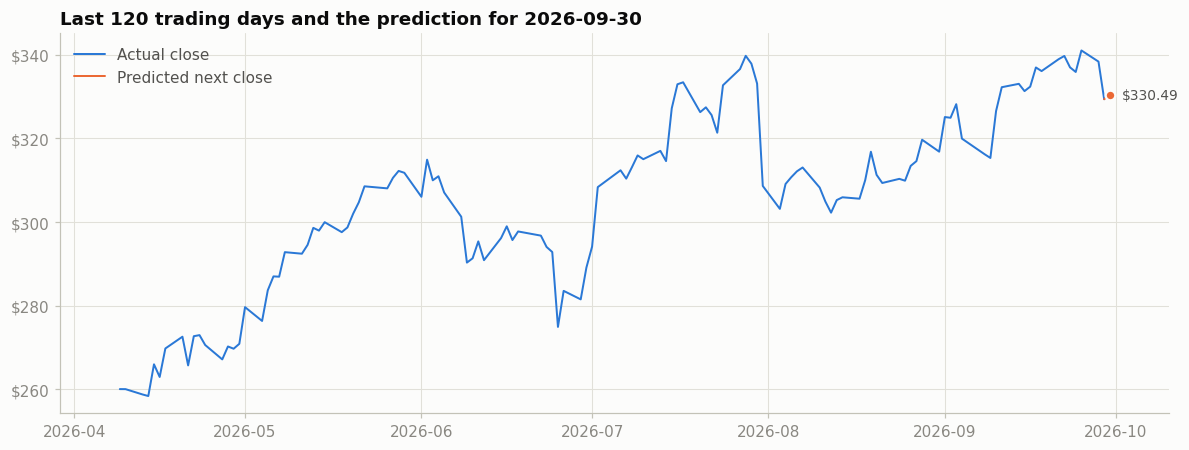

In [ ]:
plotting.plot_recent_with_prediction(df, prediction, days=120)
plt.show()

## Simulating daily use
In production the job runs every day after the close, using only data available up to that day. Here we replay the last 20 trading days: for each day we cut the data at that date, predict, and compare with what really happened next.

In [ ]:
show_source(simulate_recent)
simulation = simulate_recent(artifacts, df, days=20)
print(f"MAE over these {len(simulation)} days: ${simulation['error ($)'].abs().mean():.2f}")
print(f"Predicted too low on {(simulation['error ($)'] < 0).sum()} of {len(simulation)} days")
simulation.round(2)


<details>
<summary>View implementation of <code>simulate_recent</code></summary>

```python
def simulate_recent(artifacts: Union[str, Path, dict], df: pd.DataFrame, days: int = 20) -> pd.DataFrame:
    """Replay the last `days` trading days, using only the data known on each day."""
    if not isinstance(artifacts, dict):
        artifacts = load_artifacts(artifacts)
    rows = []
    for as_of in df.index[-(days + 1):-1]:
        p = predict_next_day(artifacts, df.loc[:as_of])
        actual_next = df["Close"].iloc[df.index.get_loc(as_of) + 1]
        rows.append({"as of": as_of.date(), "last close": p["last_close"], "predicted next": p["predicted_close"],
                     "actual next": actual_next, "error ($)": p["predicted_close"] - actual_next})
    return pd.DataFrame(rows).set_index("as of")

```

</details>


MAE over these 20 days: $3.85
Predicted too low on 10 of 20 days


,last close,predicted next,actual next,error ($)
as of,,,,
2026-08-31,316.85,317.39,325.13,-7.74
2026-09-01,325.13,325.45,324.96,0.49
2026-09-02,324.96,325.07,328.21,-3.14
2026-09-03,328.21,328.93,319.97,8.96
2026-09-04,319.97,321.03,316.22,4.81
2026-09-08,316.22,317.14,315.34,1.80
2026-09-09,315.34,316.61,326.57,-9.96
2026-09-10,326.57,326.35,332.27,-5.92
2026-09-11,332.27,332.26,333.08,-0.82


**Historical deployment demonstration.** The reloaded log-return model gave the same test metrics as in notebook 05, which confirms that the saved files work. Using historical data through September 29, 2026, it predicted a closing price of about \$330.49 for September 30, 2026, compared with the last observed close of \$329.40, a predicted increase of 0.33%. In the 20-day historical replay, it had an MAE of \$3.85 and predicted too low on 10 of the 20 days and too high on the other 10. For comparison, the originally selected raw-price model (`gru_close_volume`) predicted \$253.65 (-22.99%) for the same day, with a replay MAE of \$78.24 (see notebook 05). The log-return model's errors are small because its predictions stay close to the last close. It did not beat the naive and drift baselines, so production deployment is still not recommended.

## Operating the model (after deployment)
A deployed model needs care:
- **Data quality checks** on every new file. The loader already validates it and catches swapped columns.
- **Performance monitoring:** log each prediction, then compare it with the actual close the next day. Track a rolling MAE against the naive baseline.
- **Drift monitoring:** watch whether feature distributions (volatility, volume) move far from the training ranges.
- **Retraining:** on a schedule (for example monthly) or when monitored error degrades, retrain with the newest data and redo the evaluation before replacing the model.
- **Versioning:** keep old artifact folders so it is possible to roll back.

That closes the CRISP-DM loop: monitoring results feed back into **Business Understanding** for the next iteration.

This is the last notebook. The modeling iteration that produced the deployed model is in [`05_improvements.ipynb`](05_improvements.ipynb).